In [1]:
import NNMFit
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
import matplotlib.font_manager as font_manager
font_axis_label = {'family': 'serif',
        'color':  'black',
        'weight': 'normal',
        'size': 22,
        }
font_title = {'family': 'serif',
        'color':  'black',
        'weight': 'bold',
        'size': 20,
        }
font_legend = font_manager.FontProperties(family='serif',
                                   weight='normal',
                                   style='normal', size=13)

plt.rcParams["figure.figsize"] = (6,6)
plt.rcParams.update({'font.family':'serif'})

In [3]:
import os
save_path  = "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/unblind/step2_hese_flavor_reunblind/plots_fit_result"
os.makedirs(save_path, exist_ok=True)

In [4]:
def get_1sigma(scan, parameter, bestfit_val, threshold=1.0):
    """Find where dllh crosses threshold via sign-change detection + linear interpolation."""
    scan_sorted = scan.sort_values(parameter).reset_index(drop=True)
    x = scan_sorted[parameter].values
    delta = scan_sorted["dllh"].values - threshold

    sign_changes = np.where(np.diff(np.sign(delta)))[0]
    roots = []
    for idx in sign_changes:
        x0, x1 = x[idx], x[idx + 1]
        y0, y1 = delta[idx], delta[idx + 1]
        roots.append(x0 - y0 * (x1 - x0) / (y1 - y0))

    roots = np.array(roots)
    lower = roots[roots < bestfit_val]
    upper = roots[roots > bestfit_val]

    err_lo = bestfit_val - lower[-1] if len(lower) else np.nan
    err_hi = upper[0] - bestfit_val if len(upper) else np.nan
    return err_lo, err_hi

In [5]:
# fit with the PassingHESE passing fractions, see dag_scans/.../step2_hese_flavor_reunblind/data_fits.sh
fit_path = "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/dag_scans/flavor_globalfit/hese/unblind/step2_hese_flavor_reunblind/data_fits"

scan_dir_dict = {
    # previous fit without detector priors (`priors` key was not read by NNMFit):
    # "nbestfit50_all_param_2sigma_1D_10steps_PassingHESE": f"{fit_path}/nbestfit50_all_param_2sigma_1D_10steps_PassingHESE",
    # fit with the detector priors applied (fixed `prior` key):
    # "nbestfit50_all_param_2sigma_1D_10steps_PassingHESE_fixedprior": f"{fit_path}/nbestfit50_all_param_2sigma_1D_10steps_PassingHESE_fixedprior",
    # fixed priors and the new muon template (1 sigma template_fluctuation)
    "nbestfit50_all_param_2sigma_1D_10steps_PassingHESE_fixedprior_newmuon":
        f"{fit_path}/nbestfit50_all_param_2sigma_1D_10steps_PassingHESE_fixedprior_newmuon",
    # extra 1D scans (20 steps, finer ranges) of the signal, muon and detector parameters; combined with the scan above
    "nbestfit50_all_param_2sigma_1D_20steps_PassingHESE_fixedprior_newmuon_fine":
        f"{fit_path}/nbestfit50_all_param_2sigma_1D_20steps_PassingHESE_fixedprior_newmuon_fine",
}

In [6]:
drop_unsuccessful = True
scan_dict = {}
bestfits = {}

for name, scan_dir in scan_dir_dict.items():
    print(name)
    # use force_read if new scan points are produced
    scan_dict[name] = NNMFit.utilities.ScanHandler(scan_dir,dump=False,drop_unsuccessful=drop_unsuccessful)
    bestfits[name] = scan_dict[name].get_freefit(drop_unsuccessful="True")

nbestfit50_all_param_2sigma_1D_10steps_PassingHESE_fixedprior_newmuon
nbestfit50_all_param_2sigma_1D_20steps_PassingHESE_fixedprior_newmuon_fine


## Best fit comparison

Compare best fit parameter values across all scans and identify which optimizer found the lowest likelihood.

In [7]:
# Compare best fit values across all scans
df_compare = pd.DataFrame({name: bestfits[name] for name in scan_dir_dict}).T
display(df_compare)

best_name = df_compare["llh"].idxmin()
print(f"\nBest likelihood: '{best_name}'  (llh = {df_compare.loc[best_name, 'llh']:.6f})")
for name in scan_dir_dict:
    if name != best_name:
        delta = df_compare.loc[name, "llh"] - df_compare.loc[best_name, "llh"]
        print(f"  {name} is worse by dllh = {delta:.4f}")

,CR_grad,astro_norm,astro_nue_ratio,astro_nutau_ratio,barr_h,barr_w,barr_y,barr_z,combined_muongun_norm,conv_norm,...,fit_success,gamma_astro,ice_abs,ice_crystal,ice_holep0,ice_holep1,ice_scat,llh,muongun_asymmetry,prompt_norm
nbestfit50_all_param_2sigma_1D_10steps_PassingHESE_fixedprior_newmuon,-0.013641,3.134918,0.766208,0.037092,0.000533,0.000323,0.017505,0.012227,0.619229,1.007235,...,True,2.858755,1.0262,0.923871,0.065853,-0.062921,0.991292,180.134083,0.609508,1.416828
nbestfit50_all_param_2sigma_1D_20steps_PassingHESE_fixedprior_newmuon_fine,-0.013359,3.134629,0.766161,0.037056,0.000584,-0.000088,0.017452,0.012152,0.619262,1.007163,...,True,2.858703,1.026201,0.923873,0.065882,-0.062928,0.991291,180.134085,0.609383,1.41969



Best likelihood: 'nbestfit50_all_param_2sigma_1D_10steps_PassingHESE_fixedprior_newmuon'  (llh = 180.134083)
  nbestfit50_all_param_2sigma_1D_20steps_PassingHESE_fixedprior_newmuon_fine is worse by dllh = 0.0000


## Combined scan

The 1D scans of all scan directories merged per parameter (`CombinedScan` from `analysis_utils.py`):
dllh relative to the lowest freefit llh of all scans, and the lowest llh at equal parameter values.


In [8]:
import sys
sys.path.insert(0, "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/unblind/step2_hese_flavor_reunblind")
from analysis_utils import CombinedScan

scan_dict["combined"] = CombinedScan({name: scan_dict[name] for name in scan_dir_dict},
                                     {name: bestfits[name] for name in scan_dir_dict})
bestfits["combined"] = scan_dict["combined"].bestfit
best_name = "combined"
# the plots of the combined scan are named after the nominal scan (the first entry), so every fit iteration
# keeps its own plots
plot_tag = next(iter(scan_dir_dict))

print(f"combined best fit llh = {bestfits[best_name]['llh']:.6f}")
for parameter in ["astro_norm", "gamma_astro", "astro_nue_ratio", "astro_nutau_ratio", "combined_muongun_norm", "dom_eff"]:
    df = scan_dict[best_name].get_scan_df(param_name=parameter, drop_unsuccessful=drop_unsuccessful)
    print(f"{parameter}: {len(df)} points, {df['scan'].value_counts().to_dict()}, min dllh = {df['dllh'].min():.3g}")


combined best fit llh = 180.134083
astro_norm: 25 points, {'nbestfit50_all_param_2sigma_1D_20steps_PassingHESE_fixedprior_newmuon_fine': 18, 'nbestfit50_all_param_2sigma_1D_10steps_PassingHESE_fixedprior_newmuon': 7}, min dllh = 0.000995
gamma_astro: 21 points, {'nbestfit50_all_param_2sigma_1D_20steps_PassingHESE_fixedprior_newmuon_fine': 16, 'nbestfit50_all_param_2sigma_1D_10steps_PassingHESE_fixedprior_newmuon': 5}, min dllh = 0.00117
astro_nue_ratio: 23 points, {'nbestfit50_all_param_2sigma_1D_20steps_PassingHESE_fixedprior_newmuon_fine': 18, 'nbestfit50_all_param_2sigma_1D_10steps_PassingHESE_fixedprior_newmuon': 5}, min dllh = 0.0412
astro_nutau_ratio: 20 points, {'nbestfit50_all_param_2sigma_1D_20steps_PassingHESE_fixedprior_newmuon_fine': 14, 'nbestfit50_all_param_2sigma_1D_10steps_PassingHESE_fixedprior_newmuon': 6}, min dllh = 0.00345
combined_muongun_norm: 19 points, {'nbestfit50_all_param_2sigma_1D_20steps_PassingHESE_fixedprior_newmuon_fine': 13, 'nbestfit50_all_param_2sigm

## Free fit parameter distributions

Histograms of all free parameters across the best-fit ensemble. The red line marks the best fit value for each parameter.

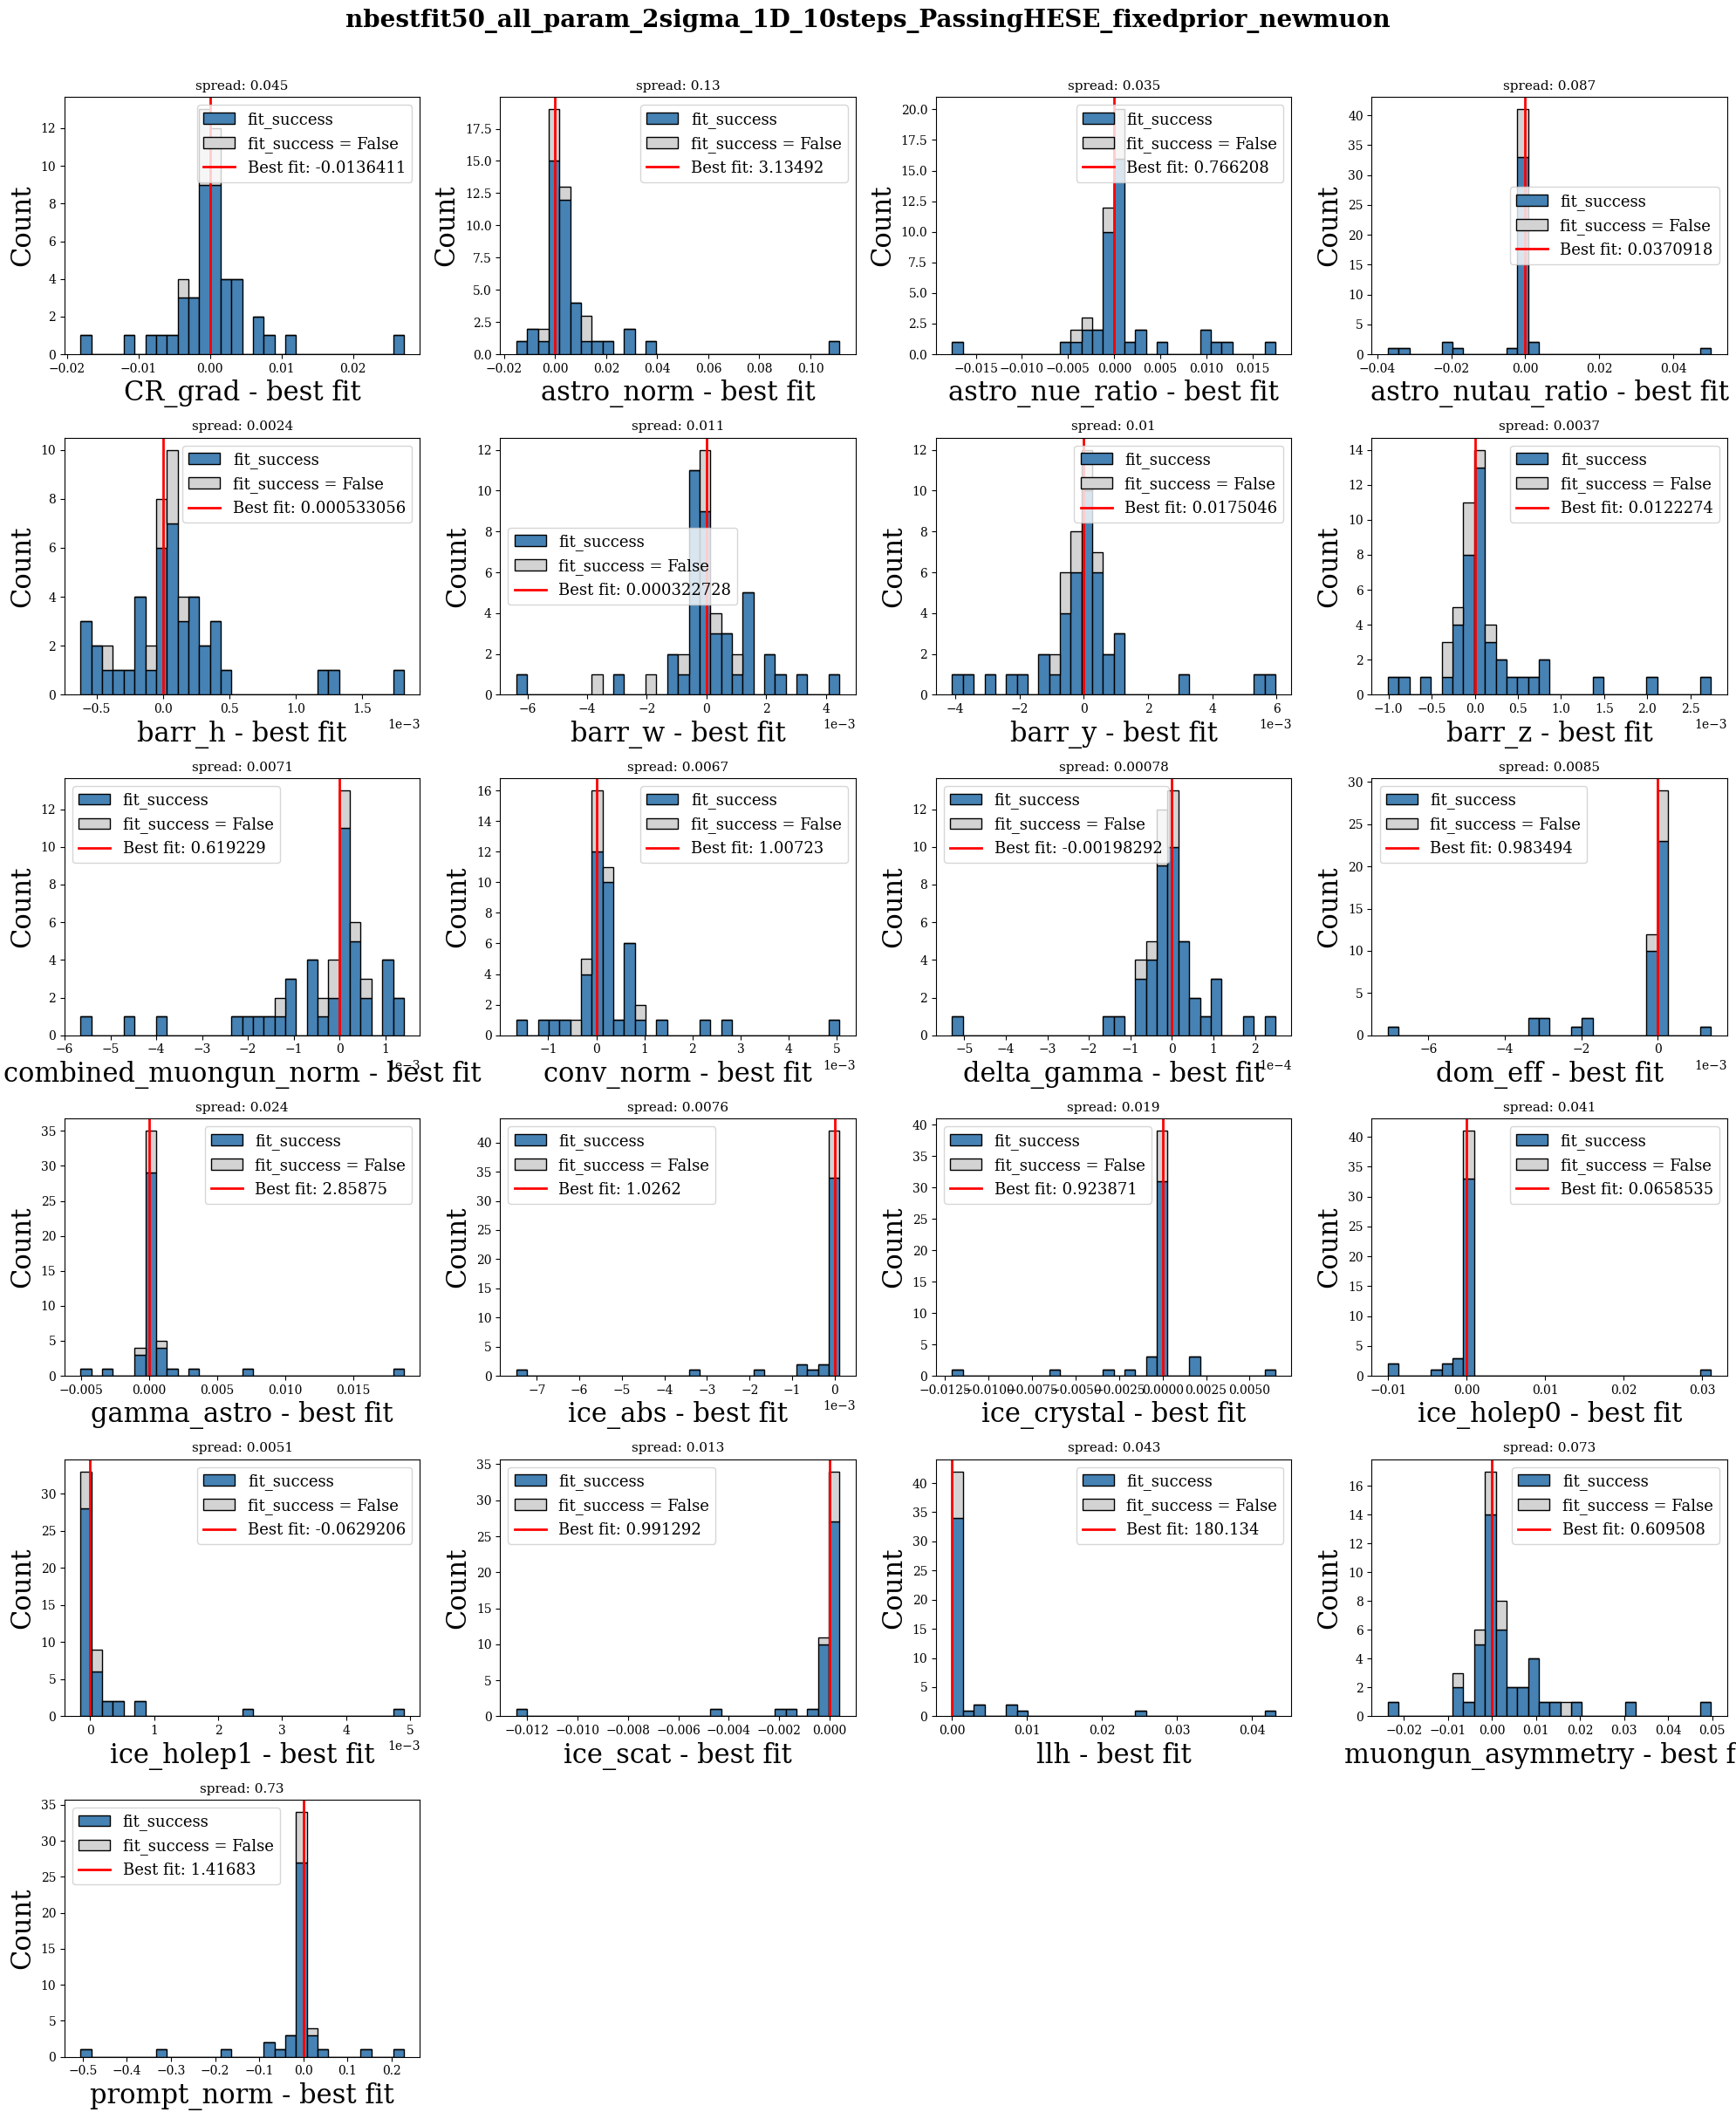

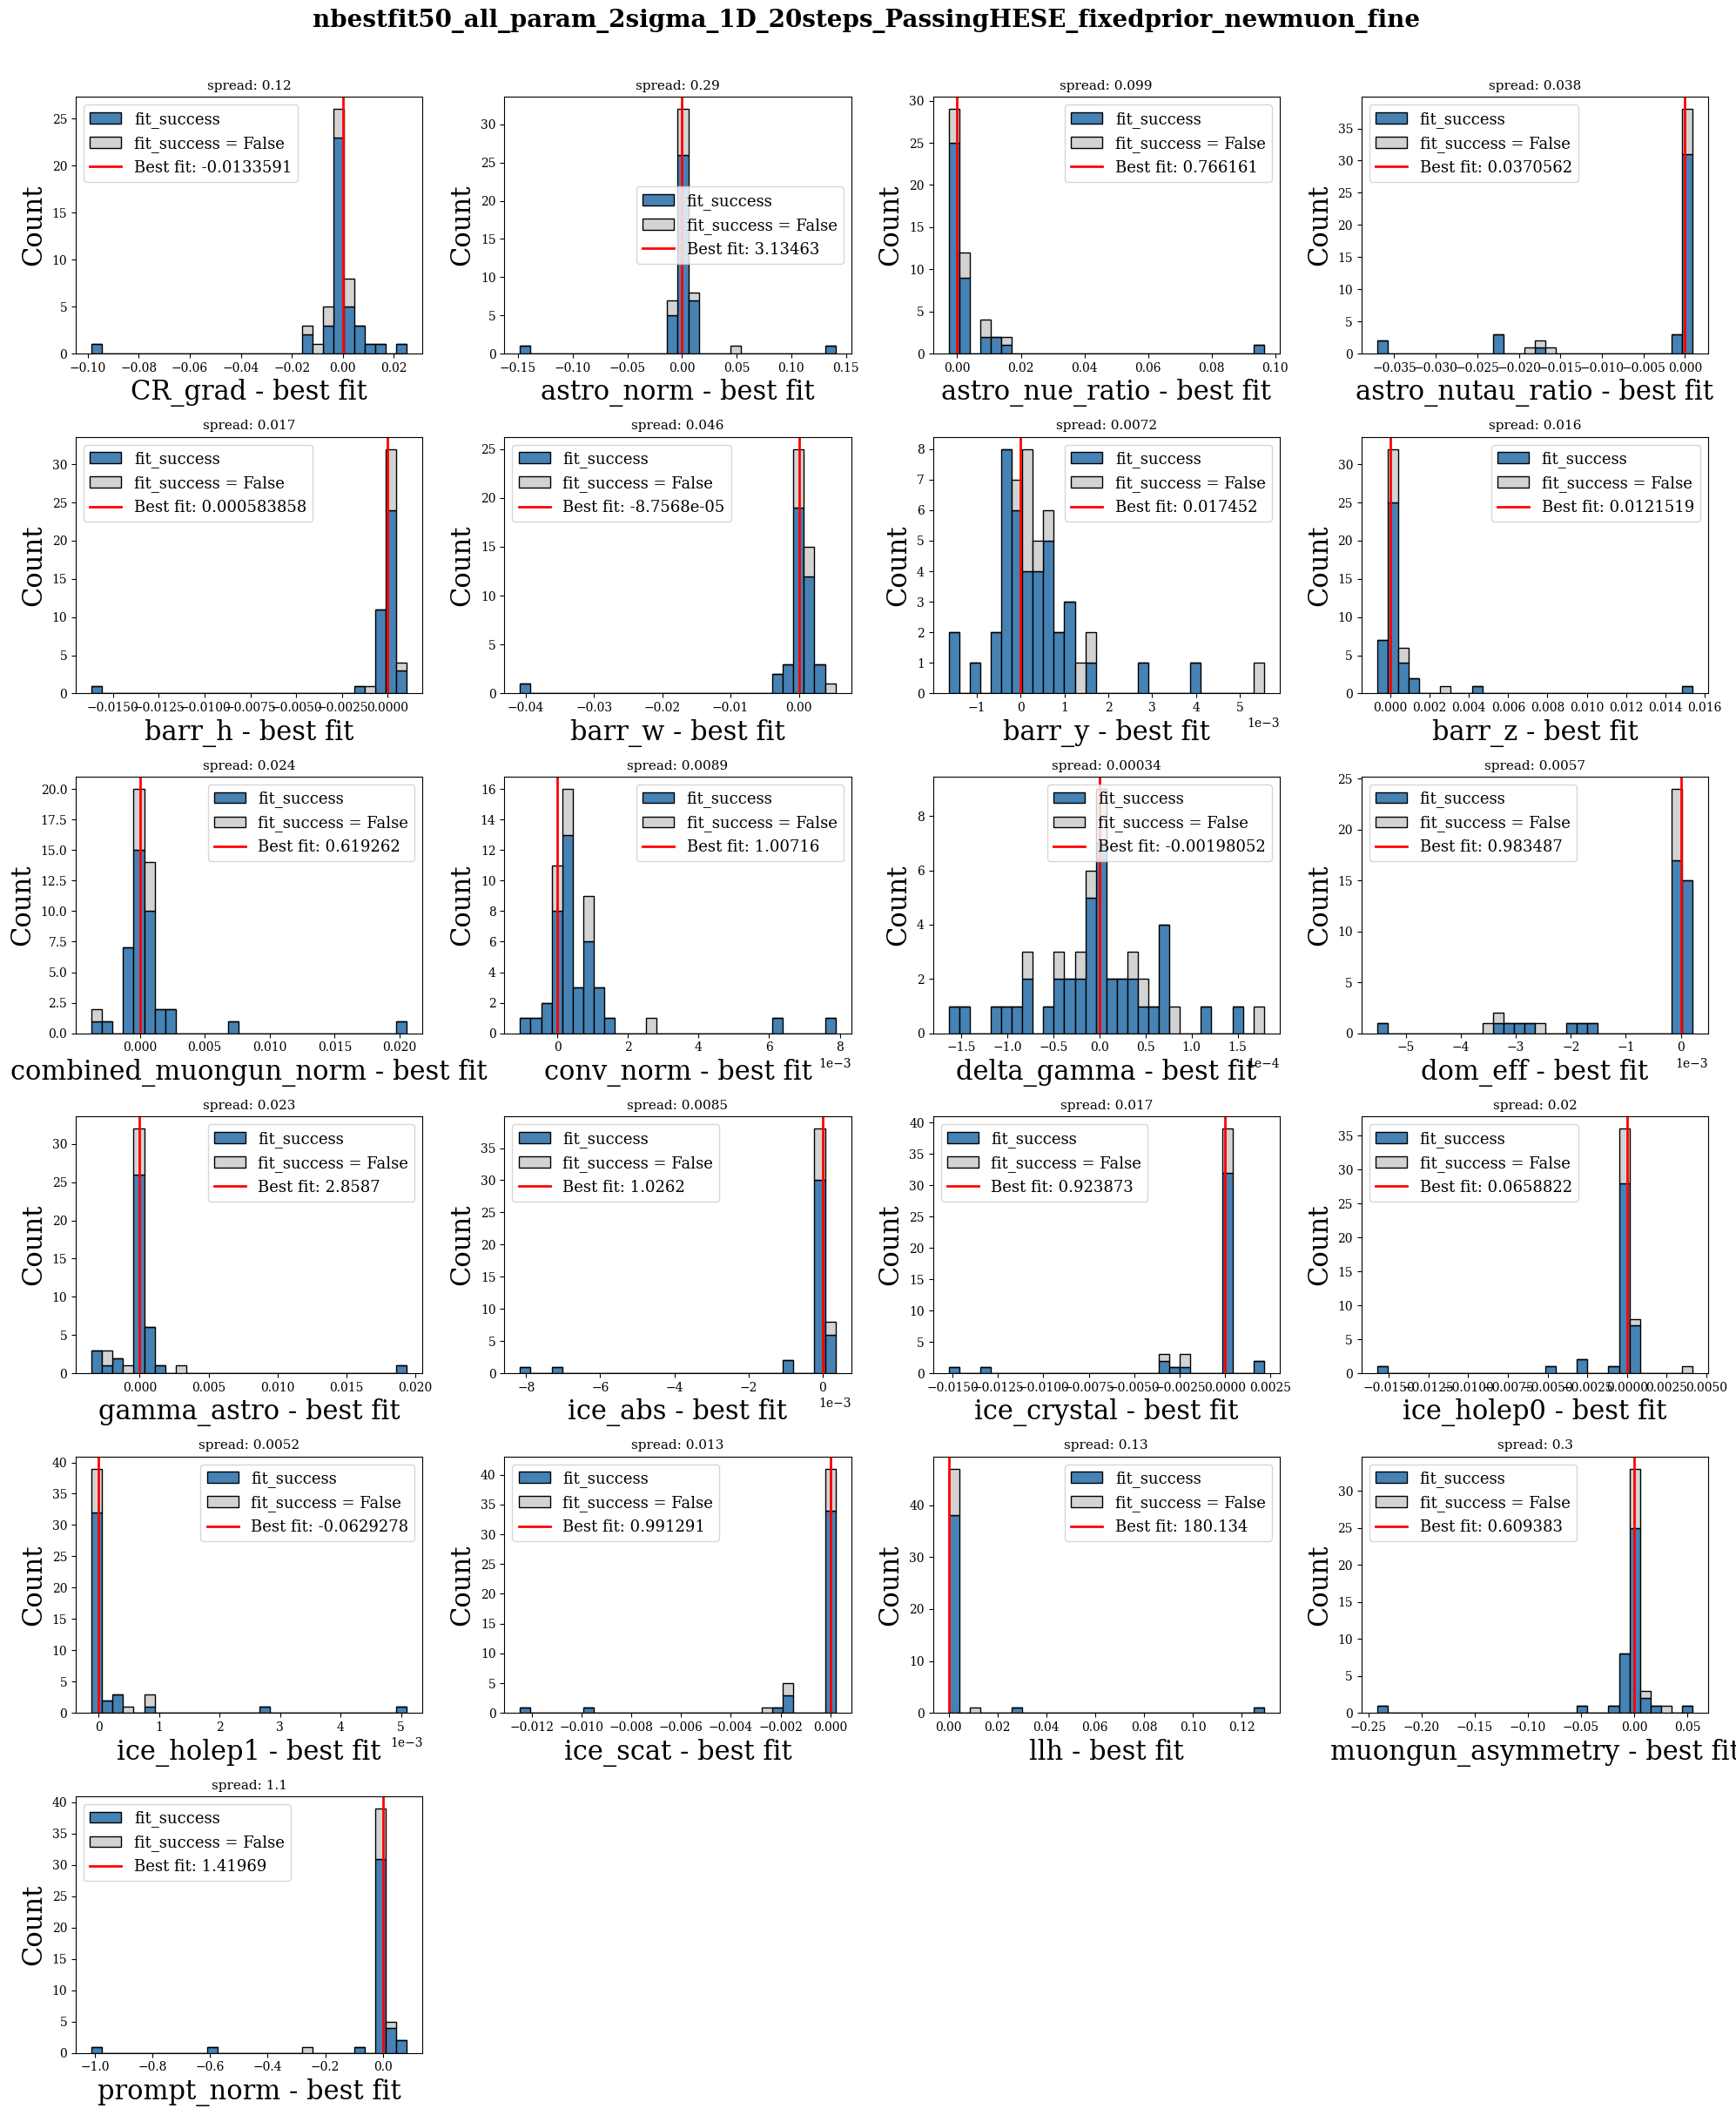

In [9]:
for name in scan_dir_dict:
    freefit_df = scan_dict[name].get_raw_df().loc["freefit"]
    success = freefit_df["fit_success"].astype(bool).values
    variables = [v for v in freefit_df.keys() if v != "fit_success"]
    bestfit = bestfits[name]

    ncols = 4
    nrows = int(np.ceil(len(variables) / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
    fig.suptitle(name, **font_title, y=1.01)
    axes = axes.flatten()

    for ax, var in zip(axes, variables):
        values = freefit_df[var].astype(float).values
        bf_val = float(bestfit[var])
        # deviation from the best fit: the freefits typically agree to 1e-6 or better, which with absolute values
        # gives unreadable offset tick labels
        delta = values - bf_val
        spread = np.nanmax(values) - np.nanmin(values)
        tiny = spread < 1e-6 * max(abs(bf_val), 1)
        bins = np.linspace(-1e-6, 1e-6, 31) if tiny else 30
        ax.hist([delta[success], delta[~success]], bins=bins, stacked=True, color=["steelblue", "lightgrey"],
                edgecolor="black", label=["fit_success", "fit_success = False"])
        ax.axvline(x=0, color="red", linewidth=2, label=f"Best fit: {bf_val:.6g}")
        ax.ticklabel_format(axis="x", useOffset=False, style="sci", scilimits=(-3, 3))
        ax.set_title(f"spread: {spread:.2g}" + (" (all freefits identical)" if tiny else ""), fontsize=11)
        ax.set_xlabel(f"{var} - best fit", fontdict=font_axis_label)
        ax.set_ylabel("Count", fontdict=font_axis_label)
        ax.legend(prop=font_legend, fontsize=9)

    for ax in axes[len(variables):]:
        ax.set_visible(False)

    plt.tight_layout()
    plt.savefig(f"{save_path}/freefit_param_hist_{name}.png", bbox_inches="tight")
    plt.show()


## Best fit parameters

Parameters from the best scan printed in `input_params` YAML format, ready to paste into the analysis config.

In [10]:
bf = bestfits[best_name]

signal      = ["astro_norm", "gamma_astro", "astro_nue_ratio", "astro_nutau_ratio"]
flux_nuis   = ["conv_norm", "prompt_norm", "combined_muongun_norm", "muongun_asymmetry",
               "CR_grad", "barr_h", "barr_w", "barr_y", "barr_z", "delta_gamma"]
det_nuis    = ["dom_eff", "ice_abs", "ice_crystal", "ice_holep0", "ice_holep1", "ice_scat"]

lines = [f"# best fit from scan: {best_name}", "input_params:"]
for label, group in [("signal", signal), ("flux nuisance", flux_nuis), ("detector nuisance", det_nuis)]:
    lines.append(f"  ### {label}")
    for p in group:
        lines.append(f"  {p}: {bf[p]}")
    lines.append("")

print("\n".join(lines))

# best fit from scan: combined
input_params:
  ### signal
  astro_norm: 3.1349179022827065
  gamma_astro: 2.858754988694502
  astro_nue_ratio: 0.7662076469912004
  astro_nutau_ratio: 0.03709176198586732

  ### flux nuisance
  conv_norm: 1.0072347305109492
  prompt_norm: 1.41682800708519
  combined_muongun_norm: 0.6192291493090364
  muongun_asymmetry: 0.6095076602673478
  CR_grad: -0.013641075274630717
  barr_h: 0.0005330560827136765
  barr_w: 0.00032272779690408767
  barr_y: 0.017504629833558313
  barr_z: 0.012227357231919369
  delta_gamma: -0.0019829183731885124

  ### detector nuisance
  dom_eff: 0.9834943074137081
  ice_abs: 1.026200150288354
  ice_crystal: 0.9238714414399262
  ice_holep0: 0.0658534593543895
  ice_holep1: -0.0629206410412576
  ice_scat: 0.9912915286581141



## All-parameter likelihood scans

$-2\Delta\log\mathcal{L}$ profiles for all 17 free parameters from the best scan. The red shaded band marks the 1σ interval; dotted verticals bound it.

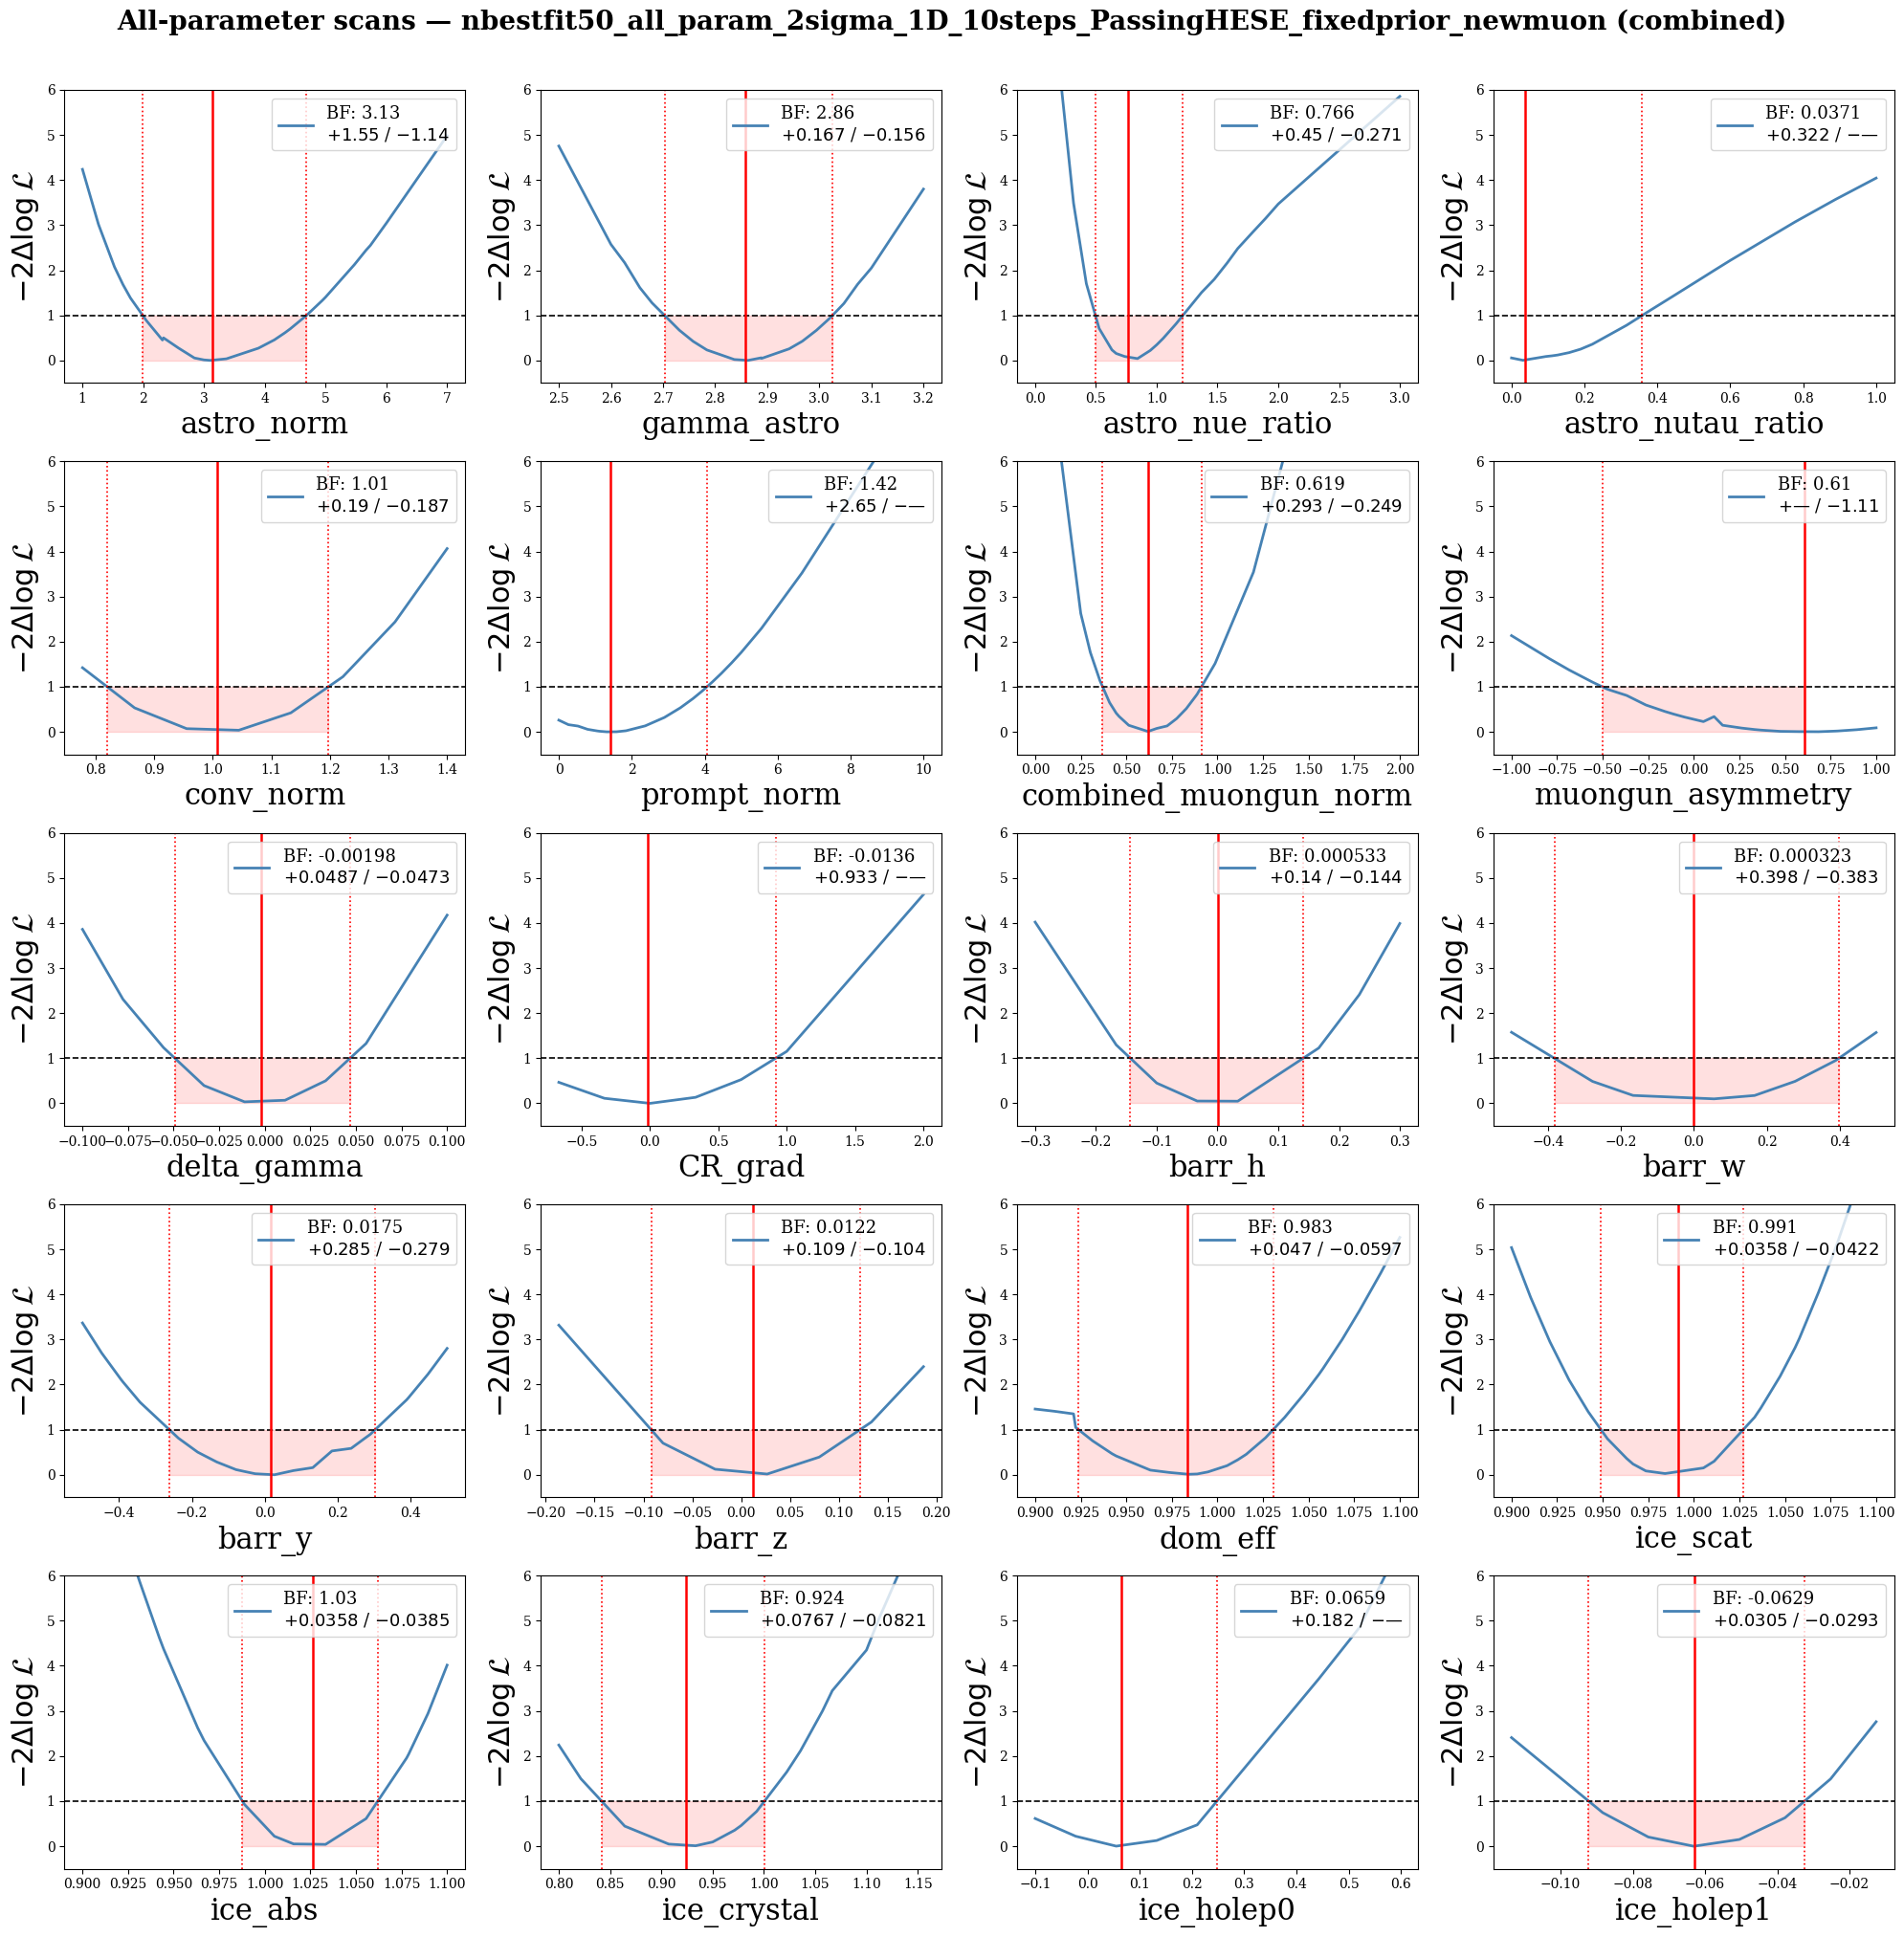

In [11]:
all_parameters = [
    "astro_norm", "gamma_astro", "astro_nue_ratio", "astro_nutau_ratio",
    "conv_norm", "prompt_norm", "combined_muongun_norm", "muongun_asymmetry",
    "delta_gamma", "CR_grad",
    "barr_h", "barr_w", "barr_y", "barr_z",
    "dom_eff", "ice_scat", "ice_abs", "ice_crystal", "ice_holep0", "ice_holep1",
]

ncols = 4
nrows = int(np.ceil(len(all_parameters) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
fig.suptitle(f"All-parameter scans — {plot_tag} (combined)", **font_title, y=1.01)
axes = axes.flatten()

scan_results = {}

for i, parameter in enumerate(all_parameters):
    ax = axes[i]
    try:
        scan = scan_dict[best_name].get_scan_df(param_name=parameter, drop_unsuccessful=drop_unsuccessful)
        bestfit_val = bestfits[best_name][parameter]
        err_lo, err_hi = get_1sigma(scan, parameter, bestfit_val)
        scan_results[parameter] = (bestfit_val, err_lo, err_hi)

        scan_sorted = scan.sort_values(parameter)
        ax.plot(scan_sorted[parameter], scan_sorted["dllh"], color="steelblue", linewidth=2)
        ax.axhline(1.0, color="black", linestyle="--", linewidth=1.2)
        ax.axvline(bestfit_val, color="red", linewidth=1.8, label=f"BF: {bestfit_val:.3g}")
        if not np.isnan(err_lo):
            ax.axvline(bestfit_val - err_lo, color="red", linestyle=":", linewidth=1.2)
            ax.fill_betweenx([0, 1], bestfit_val - err_lo,
                             bestfit_val + err_hi if not np.isnan(err_hi) else bestfit_val,
                             color="red", alpha=0.12)
        if not np.isnan(err_hi):
            ax.axvline(bestfit_val + err_hi, color="red", linestyle=":", linewidth=1.2)

        lo_str = f"{err_lo:.3g}" if not np.isnan(err_lo) else "—"
        hi_str = f"{err_hi:.3g}" if not np.isnan(err_hi) else "—"
        ax.legend([f"BF: {bestfit_val:.3g}\n$+{hi_str}$ / $-{lo_str}$"],
                  prop=font_legend, loc="upper right")
    except Exception as e:
        ax.text(0.5, 0.5, f"No scan\n({e})", ha="center", va="center", transform=ax.transAxes)
        scan_results[parameter] = (bestfits[best_name].get(parameter, np.nan), np.nan, np.nan)

    ax.set_xlabel(parameter, fontdict=font_axis_label)
    ax.set_ylabel(r"$-2\Delta\log\mathcal{L}$", fontdict=font_axis_label)
    ax.set_ylim(-0.5, 6)

for j in range(len(all_parameters), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
# named after the nominal scan, so every fit iteration keeps its own plot
plt.savefig(f"{save_path}/all_param_scan_{plot_tag}.png", bbox_inches="tight")
plt.show()


## Best fit results — LaTeX table

Best fit values with 1σ asymmetric errors for all parameters, formatted as a LaTeX table.

In [12]:
n_decimals = 3

param_labels = {
    "astro_norm":    r"$\Phi_{0,\nu_\mu}$",
    "gamma_astro":   r"$\gamma_\mathrm{astro}$",
    "conv_norm":     r"$\Phi_\mathrm{conv}$",
    "prompt_norm":   r"$\Phi_\mathrm{prompt}$",
    "astro_nue_ratio":   r"$\Phi_{\nu_e}/\Phi_{\nu_\mu}$",
    "astro_nutau_ratio": r"$\Phi_{\nu_\tau}/\Phi_{\nu_\mu}$",
    "combined_muongun_norm": r"$\Phi_\mathrm{muon}$",
    "muongun_asymmetry":     r"$a_\mathrm{muon}$",
    "delta_gamma":   r"$\Delta\gamma_{\rm CR}$",
    "CR_grad":       r"CR grad",
    "barr_h":        r"Barr $h$",
    "barr_w":        r"Barr $w$",
    "barr_y":        r"Barr $y$",
    "barr_z":        r"Barr $z$",
    "dom_eff":       r"DOM eff.",
    "ice_scat":      r"Ice scattering",
    "ice_abs":       r"Ice absorption",
    "ice_crystal":   r"Ice crystal",
    "ice_holep0":    r"Ice hole $p_0$",
    "ice_holep1":    r"Ice hole $p_1$",
}

group_labels = {
    "astro_norm":   "Signal",
    "gamma_astro":  None,
    "conv_norm":    "Flux nuisance",
    "prompt_norm":  None,
    "astro_nue_ratio":   None,
    "astro_nutau_ratio": None,
    "combined_muongun_norm": None,
    "muongun_asymmetry":     None,
    "delta_gamma":  None,
    "CR_grad":      None,
    "barr_h":       None,
    "barr_w":       None,
    "barr_y":       None,
    "barr_z":       None,
    "dom_eff":      "Detector nuisance",
    "ice_scat":     None,
    "ice_abs":      None,
    "ice_crystal":  None,
    "ice_holep0":   None,
    "ice_holep1":   None,
}

lines = [
    r"\begin{table}[h]",
    r"  \centering",
    r"  \caption{Best fit values with $1\sigma$ asymmetric uncertainties.}",
    r"  \label{tab:bestfit}",
    r"  \begin{tabular}{l r r r}",
    r"    \hline\hline",
    r"    Parameter & Best fit & $-1\sigma$ & $+1\sigma$ \\",
    r"    \hline",
]

def fmt(v):
    return r"---" if np.isnan(v) else f"{v:.{n_decimals}f}"

current_group = None
for p in all_parameters:
    grp = group_labels.get(p)
    if grp is not None and grp != current_group:
        lines.append(r"    \hline")
        lines.append(r"    \multicolumn{4}{l}{\textbf{" + grp + r"}} \\")
        lines.append(r"    \hline")
        current_group = grp

    bf_val, err_lo, err_hi = scan_results.get(p, (bestfits[best_name].get(p, float("nan")), float("nan"), float("nan")))
    label = param_labels.get(p, p)
    lines.append(f"    {label} & ${fmt(bf_val)}$ & ${fmt(err_lo)}$ & ${fmt(err_hi)}$ \\\\")

lines += [
    r"    \hline\hline",
    r"  \end{tabular}",
    r"\end{table}",
]

latex = "\n".join(lines)
print(latex)


\begin{table}[h]
  \centering
  \caption{Best fit values with $1\sigma$ asymmetric uncertainties.}
  \label{tab:bestfit}
  \begin{tabular}{l r r r}
    \hline\hline
    Parameter & Best fit & $-1\sigma$ & $+1\sigma$ \\
    \hline
    \hline
    \multicolumn{4}{l}{\textbf{Signal}} \\
    \hline
    $\Phi_{0,\nu_\mu}$ & $3.135$ & $1.144$ & $1.552$ \\
    $\gamma_\mathrm{astro}$ & $2.859$ & $0.156$ & $0.167$ \\
    $\Phi_{\nu_e}/\Phi_{\nu_\mu}$ & $0.766$ & $0.271$ & $0.450$ \\
    $\Phi_{\nu_\tau}/\Phi_{\nu_\mu}$ & $0.037$ & $---$ & $0.322$ \\
    \hline
    \multicolumn{4}{l}{\textbf{Flux nuisance}} \\
    \hline
    $\Phi_\mathrm{conv}$ & $1.007$ & $0.187$ & $0.190$ \\
    $\Phi_\mathrm{prompt}$ & $1.417$ & $---$ & $2.646$ \\
    $\Phi_\mathrm{muon}$ & $0.619$ & $0.249$ & $0.293$ \\
    $a_\mathrm{muon}$ & $0.610$ & $1.112$ & $---$ \\
    $\Delta\gamma_{\rm CR}$ & $-0.002$ & $0.047$ & $0.049$ \\
    CR grad & $-0.014$ & $---$ & $0.933$ \\
    Barr $h$ & $0.001$ & $0.144$ & $0.140$ \\
  

## Comparison with previous analyses

Side-by-side LaTeX table of best fit values from HESE-7.5 (single power law, no flavor fit), HESE-7.5 flavor,
HESE-12 flavor and this analysis. The HESE-7.5 flavor composition is converted to the flavor scalings used
here, with $\Phi_\mathrm{astro} = \Phi_{0,\nu_\mu}(1 + s_{\nu_e} + s_{\nu_\tau})$.


In [13]:
# (best_fit, err_lo, err_hi); err_lo/err_hi None = no error available; entry None = parameter not in that analysis.

# HESE-7.5, single power law without flavor fit: values given as (bf, CL_lo, CL_hi)
hese75_results = {
    "astro_norm":   (6.37/3,  6.37/3 - 4.75/3,  7.83/3 - 6.37/3),
    "gamma_astro":  (2.87,    2.87 - 2.68,       3.08 - 2.87),
    "conv_norm":    (1.01,    1.01 - 0.67,        1.35 - 1.01),
    "prompt_norm":  (0.0,     0.0,                5.34 - 0.0),
    "combined_muongun_norm": (1.19,    1.19 - 0.75,        1.64 - 1.19),
    "delta_gamma":  (-0.053,  -0.053 - (-0.184),  -0.005 - (-0.053)),
    "dom_eff":      (0.952,   0.952 - 0.886,      1.045 - 0.952),
}

# HESE-7.5 flavor: Phi_astro = 6.98 (all flavors), nu_e : nu_mu : nu_tau = 0.29 : 0.43 : 0.28.
# With Phi_astro = astro_norm * (1 + astro_nue_ratio + astro_nutau_ratio):
#   astro_norm = f_mu * Phi_astro, astro_nue_ratio = f_e / f_mu, astro_nutau_ratio = f_tau / f_mu
hese75_phi_astro = 6.98
hese75_f_e, hese75_f_mu, hese75_f_tau = 0.29, 0.43, 0.28
hese75_flavor_results = {
    "astro_norm":        (hese75_f_mu * hese75_phi_astro, None, None),
    "astro_nue_ratio":   (hese75_f_e / hese75_f_mu,       None, None),
    "astro_nutau_ratio": (hese75_f_tau / hese75_f_mu,     None, None),
    "gamma_astro":       (2.89, 0.20, 0.21),
    "conv_norm":         (0.97, 0.36, 0.36),
    "prompt_norm":       (0.0,  0.0,  6.1),
    "combined_muongun_norm": (1.16, 0.45, 0.46),
}

# HESE-12 flavor
hese12_results = {
    "astro_norm":   (2.53,    1.49,   1.78),
    "gamma_astro":  (2.84,    0.18,   0.19),
    "astro_nue_ratio":   (0.45,  0.40, 0.68),
    "astro_nutau_ratio": (0.896, 0.89, 1.34),
    "conv_norm":    (0.99,    0.20,   0.19),
    "prompt_norm":  (0.0,     0.0,    2.25),
    "combined_muongun_norm": (1.16,    0.43,   0.42),
    "delta_gamma":  (-0.00,   1.0,    1.0),
    "CR_grad":      (0.042,   1.0,    2.0),
    "barr_h":       (0.0,     0.5,    0.5),
    "barr_w":       (0.0,     0.5,    0.5),
    "barr_y":       (0.0,     0.5,    0.5),
    "barr_z":       (0.0,     0.5,    0.5),
    "dom_eff":      (1.04,    0.04,   0.06),
    "ice_scat":     (0.98,    0.04,   0.04),
    "ice_abs":      (0.99,    0.04,   0.04),
    "ice_holep0":   (-0.27,   0.38,   0.28),
    "ice_holep1":   (-0.08,   0.05,   0.04),
}

def _missing(v):
    return v is None or np.isnan(v)

def fmt_entry(entry):
    if entry is None:
        return "---"
    bf, lo, hi = entry
    if _missing(lo) and _missing(hi):
        return f"${bf:.{n_decimals}f}$"
    hi_str = "---" if _missing(hi) else f"+{hi:.{n_decimals}f}"
    lo_str = "---" if _missing(lo) else f"-{lo:.{n_decimals}f}"
    return f"${bf:.{n_decimals}f}^{{{hi_str}}}_{{{lo_str}}}$"

lines = [
    r"\begin{table}[h]",
    r"  \centering",
    r"  \caption{Comparison of best fit values with $1\sigma$ asymmetric uncertainties"
    r" across analyses.}",
    r"  \label{tab:bestfit_comparison_flavor}",
    r"  \begin{tabular}{l r r r r}",
    r"    \hline\hline",
    r"    Parameter & HESE-7.5 & HESE-7.5 flavor & HESE-12 flavor & This analysis \\",
    r"    \hline",
]

current_group = None
for p in all_parameters:
    grp = group_labels.get(p)
    if grp is not None and grp != current_group:
        lines.append(r"    \hline")
        lines.append(r"    \multicolumn{5}{l}{\textbf{" + grp + r"}} \\")
        lines.append(r"    \hline")
        current_group = grp

    h75  = fmt_entry(hese75_results.get(p))
    h75f = fmt_entry(hese75_flavor_results.get(p))
    h12  = fmt_entry(hese12_results.get(p))
    curr = fmt_entry(scan_results.get(p, (bestfits[best_name].get(p, float("nan")), float("nan"), float("nan"))))

    label = param_labels.get(p, p)
    lines.append(f"    {label} & {h75} & {h75f} & {h12} & {curr} \\\\")

lines += [
    r"    \hline\hline",
    r"  \end{tabular}",
    r"\end{table}",
]

latex_comparison = "\n".join(lines)
print(latex_comparison)


\begin{table}[h]
  \centering
  \caption{Comparison of best fit values with $1\sigma$ asymmetric uncertainties across analyses.}
  \label{tab:bestfit_comparison_flavor}
  \begin{tabular}{l r r r r}
    \hline\hline
    Parameter & HESE-7.5 & HESE-7.5 flavor & HESE-12 flavor & This analysis \\
    \hline
    \hline
    \multicolumn{5}{l}{\textbf{Signal}} \\
    \hline
    $\Phi_{0,\nu_\mu}$ & $2.123^{+0.487}_{-0.540}$ & $3.001$ & $2.530^{+1.780}_{-1.490}$ & $3.135^{+1.552}_{-1.144}$ \\
    $\gamma_\mathrm{astro}$ & $2.870^{+0.210}_{-0.190}$ & $2.890^{+0.210}_{-0.200}$ & $2.840^{+0.190}_{-0.180}$ & $2.859^{+0.167}_{-0.156}$ \\
    $\Phi_{\nu_e}/\Phi_{\nu_\mu}$ & --- & $0.674$ & $0.450^{+0.680}_{-0.400}$ & $0.766^{+0.450}_{-0.271}$ \\
    $\Phi_{\nu_\tau}/\Phi_{\nu_\mu}$ & --- & $0.651$ & $0.896^{+1.340}_{-0.890}$ & $0.037^{+0.322}_{---}$ \\
    \hline
    \multicolumn{5}{l}{\textbf{Flux nuisance}} \\
    \hline
    $\Phi_\mathrm{conv}$ & $1.010^{+0.340}_{-0.340}$ & $0.970^{+0.360}_{-0.36